# Lab 12 — Training an Imaging Model: From Scratch versus Transfer Learning

**AI in Healthcare · Unit IV · B.Tech AI, Third Year · About 120 minutes**
**Lecture:** [Session 2 — Model development and training](../lectures/session-02-model-development-training.md)
**Runs on:** Kaggle Notebooks with a GPU (see Setup). A CPU works but is much slower.

## Objectives

In the lecture you saw that an image classifier has millions of parameters but only a few thousand labelled images to learn from. In this lab you measure what that means in practice:

1. **Describe the data and its limits** before training: class balance, unit of analysis, and how the splits were made.
2. **Set a baseline**: a trivial model and a logistic regression on pixels.
3. **Train a small CNN from scratch** and read its learning curves.
4. **Use transfer learning**: a ResNet-18 pretrained on ImageNet, first as a fixed feature extractor, then fine-tuned, with and without augmentation.
5. **Choose, freeze, and test once**: pick a model and threshold on validation data only, then evaluate on the test set a single time.

**Prerequisites:** Session 2 lecture notes; Lab 4 (sensitivity, specificity, PPV, NPV, AUROC); the Unit II ECG notebook (a PyTorch training loop). No medical knowledge is needed.

## Task, data and unit of analysis

| Element | This lab |
|---|---|
| Clinical motivation | Pneumonia (a lung infection) often shows as whiter, more opaque areas on a chest X-ray |
| Computational task | Binary classification: *normal* (0) or *pneumonia* (1) |
| Unit of analysis | **One image**, not one patient |
| Data | PneumoniaMNIST from MedMNIST v2, 64 × 64 greyscale, derived from 5,856 paediatric chest X-rays (Kermany et al., 2018) |
| Licence | CC BY 4.0 (per [medmnist.com](https://medmnist.com/), checked October 2026) |

This is an educational exercise. A 64 × 64 image is far below diagnostic resolution, the data come from one source population, and nothing you train here is a diagnostic tool.

## Deliverables

Submit this notebook, run from top to bottom, with:

- all `TODO` code completed and the checks passing;
- every ✍️ answer written in its cell;
- the final comparison table and the test-set result from Part 5;
- the reflection in Part 6.

## Setup — 10 minutes

**On Kaggle:** create a notebook, upload this file (*File → Import Notebook*), then open the right-hand *Settings* panel:

- **Accelerator:** GPU (for example *GPU T4 x2* or *GPU P100*). One GPU is used.
- **Internet:** on. The first run downloads two files:

| File | Source | Size | Saved to |
|---|---|---|---|
| `pneumoniamnist_64.npz` | [Zenodo record 10519652](https://zenodo.org/records/10519652) (MedMNIST v2) | about 21 MB | `lab12_data/` |
| ResNet-18 ImageNet weights | PyTorch (torchvision) | about 45 MB | `lab12_data/torch/` |

**No extra packages are installed.** The lab uses PyTorch, torchvision, scikit-learn, pandas and matplotlib, which Kaggle's Python image already provides. It does not need the `medmnist` package: it reads the dataset file directly and checks its MD5 checksum.

**Internet switched off?** Download `pneumoniamnist_64.npz` from the Zenodo link yourself, add it to the notebook as a Kaggle dataset, and the next cell will find it under `/kaggle/input/`.

**Files written.** Everything goes into `lab12_data/` (on Kaggle, `/kaggle/working/lab12_data/`). A rerun reuses the downloads and **overwrites** `lab12_results.csv` and `lab12_chosen_model.pt`. Do not commit these files to a repository.

**Expected run time:** a few minutes of training in total on one GPU; roughly 30–60 minutes on a CPU.

In [1]:
import hashlib
import os
import random
import time
import urllib.request
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ON_KAGGLE = Path("/kaggle/working").is_dir()
DATA_DIR = (Path("/kaggle/working") if ON_KAGGLE else Path.cwd()) / "lab12_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
os.environ["TORCH_HOME"] = str(DATA_DIR / "torch")   # pretrained weights are cached here

print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | scikit-learn {sklearn.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU found")
print("data directory:", DATA_DIR)
if DEVICE.type == "cpu":
    print("WARNING: running on CPU. Training will be slow; on Kaggle, switch the accelerator to GPU.")


def check(description, condition):
    print(("PASS  " if condition else "CHECK ") + description)

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | scikit-learn 1.6.1
device: cuda | Tesla T4
data directory: /kaggle/working/lab12_data


In [2]:
DATA_URL = "https://zenodo.org/records/10519652/files/pneumoniamnist_64.npz?download=1"
DATA_MD5 = "8f4eceb4ccffa70c672198ea285246c6"   # published in the MedMNIST package metadata


def md5sum(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


attached = sorted(Path("/kaggle/input").glob("**/pneumoniamnist_64.npz")) if ON_KAGGLE else []
DATA_FILE = attached[0] if attached else DATA_DIR / "pneumoniamnist_64.npz"
if not DATA_FILE.exists():
    print("Downloading PneumoniaMNIST (64 x 64), about 21 MB ...")
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)
if md5sum(DATA_FILE) != DATA_MD5:
    raise ValueError(f"{DATA_FILE} does not match the published checksum; delete it and rerun.")

data = np.load(DATA_FILE)
SPLITS = ("train", "val", "test")
IMAGES = {s: data[f"{s}_images"] for s in SPLITS}                     # uint8, shape (n, 64, 64)
LABELS = {s: data[f"{s}_labels"].ravel().astype(int) for s in SPLITS}  # 0 = normal, 1 = pneumonia
CLASS_NAMES = {0: "normal", 1: "pneumonia"}
print("loaded", DATA_FILE)
for s in SPLITS:
    print(f"{s:5}  images {IMAGES[s].shape}  labels {LABELS[s].shape}")

loaded /kaggle/working/lab12_data/pneumoniamnist_64.npz
train  images (4708, 64, 64)  labels (4708,)
val    images (524, 64, 64)  labels (524,)
test   images (624, 64, 64)  labels (624,)


## Part 1 — Know the data before training (15 minutes)

`IMAGES[split]` is a NumPy array of shape `(n, 64, 64)`: *n* images of 64 × 64 pixels, each pixel an integer from 0 (black) to 255 (white). `LABELS[split]` holds one label per image.

### Exercise 1.1 — Split summary

Complete `split_summary()` so it returns a DataFrame with one row per split and the columns `split`, `images`, `normal`, `pneumonia` and `pneumonia_fraction`.

In [3]:
def split_summary():
    rows = []
    for s in SPLITS:
        y = LABELS[s]
        normal = int((y == 0).sum())
        pneumonia = int((y == 1).sum())
        rows.append({"split": s, "images": int(len(y)), "normal": normal,
                     "pneumonia": pneumonia, "pneumonia_fraction": pneumonia / len(y)})
    return pd.DataFrame(rows)


summary = split_summary()
display(summary)
check("train has 4,708 images", summary.loc[summary.split == "train", "images"].iloc[0] == 4708)
check("train has 3,494 pneumonia images", summary.loc[summary.split == "train", "pneumonia"].iloc[0] == 3494)


,split,images,normal,pneumonia,pneumonia_fraction
0,train,4708,1214,3494,0.742141
1,val,524,135,389,0.742366
2,test,624,234,390,0.625000


PASS  train has 4,708 images
PASS  train has 3,494 pneumonia images


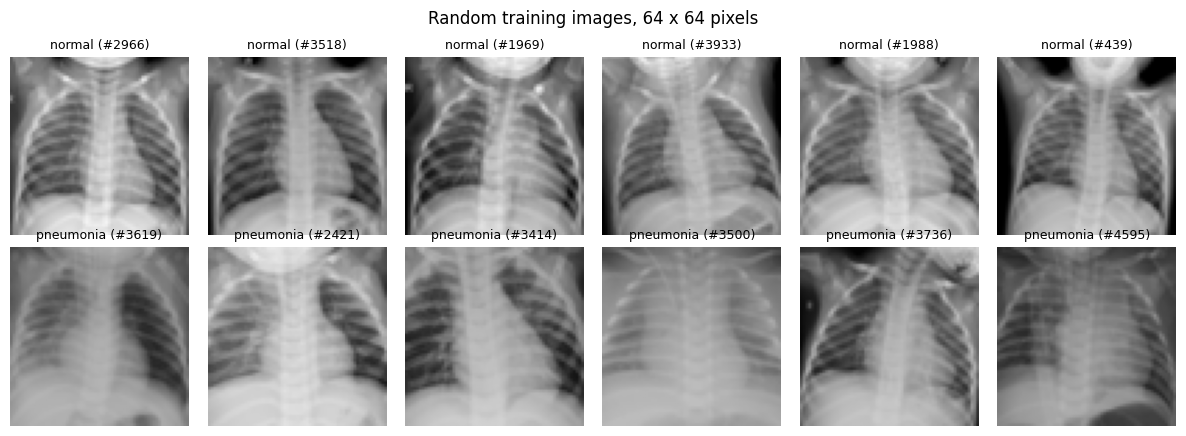

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
rng = np.random.default_rng(SEED)
for row, label in enumerate((0, 1)):
    idx = rng.choice(np.flatnonzero(LABELS["train"] == label), size=6, replace=False)
    for ax, i in zip(axes[row], idx):
        ax.imshow(IMAGES["train"][i], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{CLASS_NAMES[label]} (#{i})", fontsize=9)
        ax.axis("off")
fig.suptitle("Random training images, 64 x 64 pixels")
plt.tight_layout()
plt.show()

**How the splits were made.** According to the MedMNIST metadata, the source dataset had a training set and a separate held-out set. MedMNIST split the source training set **randomly, 9:1**, into the `train` and `val` sets here, and used the source held-out set as `test`. The files contain **no patient identifiers**.

### Exercise 1.2 — Interpret

✍️ **Your answer** (4–6 sentences):

1. What does one row of the data represent? Why is "4,708 training images" not the same as "4,708 children"?
2. The `val` set was cut randomly from the same pool as `train`. Why might validation results be **optimistic**?
3. The pneumonia fraction differs between `val` and `test`. Name one metric from Lab 4 that will change because of this, even if the model itself does not change.
4. Is the pneumonia fraction here the prevalence a children's clinic would see? Why does that matter?

## Part 2 — Metrics and baselines (15 minutes)

Every model in this lab outputs a **probability of pneumonia** for each image. A **threshold** turns probabilities into decisions: probability ≥ threshold means "pneumonia".

### Exercise 2.1 — Metrics at a threshold

Complete `binary_metrics`. Use the confusion-matrix counts: TP (pneumonia called pneumonia), FN (pneumonia missed), TN, FP. Return `None` for a metric whose denominator is zero. AUROC is already filled in; it does not depend on the threshold.

In [5]:
def binary_metrics(y_true, p, threshold=0.5):
    y_true = np.asarray(y_true)
    p = np.asarray(p)
    y_hat = (p >= threshold).astype(int)
    tp = int(((y_hat == 1) & (y_true == 1)).sum())
    fn = int(((y_hat == 0) & (y_true == 1)).sum())
    tn = int(((y_hat == 0) & (y_true == 0)).sum())
    fp = int(((y_hat == 1) & (y_true == 0)).sum())
    auroc = roc_auc_score(y_true, p) if len(np.unique(p)) > 1 else 0.5
    ratio = lambda a, b: (a / b) if b else None
    return {"auroc": auroc, "sensitivity": ratio(tp, tp + fn),
            "specificity": ratio(tn, tn + fp), "ppv": ratio(tp, tp + fp),
            "npv": ratio(tn, tn + fn), "accuracy": ratio(tp + tn, tp + fn + tn + fp),
            "tp": tp, "fn": fn, "tn": tn, "fp": fp}


toy = binary_metrics([1, 1, 1, 0, 0], [0.9, 0.8, 0.2, 0.6, 0.1])
check("sensitivity 2/3", toy["sensitivity"] is not None and abs(toy["sensitivity"] - 2 / 3) < 1e-9)
check("specificity 1/2", toy["specificity"] == 0.5)
check("PPV 2/3", toy["ppv"] is not None and abs(toy["ppv"] - 2 / 3) < 1e-9)
check("NPV 1/2", toy["npv"] == 0.5)


PASS  sensitivity 2/3
PASS  specificity 1/2
PASS  PPV 2/3
PASS  NPV 1/2


### Two baselines

- **Trivial baseline:** give every image the training pneumonia fraction as its probability. With a 0.5 threshold it calls every image "pneumonia".
- **Logistic regression on pixels:** each image is shrunk to 32 × 32 by averaging 2 × 2 blocks, flattened to 1,024 numbers, and scaled to 0–1. Logistic regression learns one weight per pixel.

All results in Parts 2–4 are on the **validation** set. The test set is not touched until Part 5. `VAL_PRED` collects each model's validation probabilities, and `MODELS` keeps each trained model for Part 5.

In [6]:
VAL_PRED = {}   # model name -> validation probabilities
MODELS = {}     # model name -> object with a predict(images) method returning probabilities


def val_table():
    rows = [{"model": name, **binary_metrics(LABELS["val"], p)} for name, p in VAL_PRED.items()]
    cols = ["model", "auroc", "sensitivity", "specificity", "ppv", "npv", "accuracy"]
    return pd.DataFrame(rows)[cols].round(3)


class TrivialBaseline:
    def __init__(self, train_labels):
        self.rate = float(np.mean(train_labels))

    def predict(self, images):
        return np.full(len(images), self.rate)


def pixels_32(images):
    x = images.astype(np.float32) / 255.0
    x = x.reshape(len(x), 32, 2, 32, 2).mean(axis=(2, 4))   # average 2 x 2 blocks: 64 x 64 -> 32 x 32
    return x.reshape(len(x), -1)


class PixelLogReg:
    def __init__(self):
        self.clf = LogisticRegression(C=0.1, max_iter=2000)

    def fit(self, images, labels):
        self.clf.fit(pixels_32(images), labels)
        return self

    def predict(self, images):
        return self.clf.predict_proba(pixels_32(images))[:, 1]


t0 = time.time()
MODELS["trivial"] = TrivialBaseline(LABELS["train"])
MODELS["logreg_pixels"] = PixelLogReg().fit(IMAGES["train"], LABELS["train"])
for name in ("trivial", "logreg_pixels"):
    VAL_PRED[name] = MODELS[name].predict(IMAGES["val"])
print(f"baselines fitted in {time.time() - t0:.1f} s")
val_table()

baselines fitted in 2.2 s


,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956


### Exercise 2.2 — Interpret the baselines

✍️ **Your answer** (3–4 sentences):

1. What are the trivial baseline's accuracy, sensitivity and specificity? Why is its accuracy high but its usefulness zero?
2. Why is AUROC exactly 0.5 for the trivial baseline?
3. Logistic regression has no idea what a lung is. What does its validation AUROC tell you about how hard this task is at 64 × 64?

## Part 3 — A small CNN trained from scratch (25 minutes)

### Preparing tensors

PyTorch models take tensors of shape `(n, channels, height, width)`. Our images become `(n, 1, 64, 64)` floats between 0 and 1.

The small CNN normalises its input with the **mean and standard deviation of the training images only**, the same rule as fitting `StandardScaler` on the training set in Lab 4.

In [7]:
TENSORS = {s: torch.from_numpy(IMAGES[s]).float().div(255.0).unsqueeze(1) for s in SPLITS}
TARGETS = {s: torch.from_numpy(LABELS[s]).float() for s in SPLITS}
TRAIN_MEAN = TENSORS["train"].mean().item()
TRAIN_STD = TENSORS["train"].std().item()
print("tensor shape:", tuple(TENSORS["train"].shape), f"| train mean {TRAIN_MEAN:.3f}, std {TRAIN_STD:.3f}")

# Class imbalance: about 74% of training images are pneumonia. pos_weight < 1 makes each pneumonia
# image count less in the loss, so the minority "normal" class is not ignored.
n_pos = int(LABELS["train"].sum())
n_neg = len(LABELS["train"]) - n_pos
POS_WEIGHT = torch.tensor([n_neg / n_pos])
print(f"pos_weight = {n_neg} / {n_pos} = {POS_WEIGHT.item():.3f}")

tensor shape: (4708, 1, 64, 64) | train mean 0.572, std 0.174
pos_weight = 1214 / 3494 = 0.347


### The model and the training loop

`SmallCNN` has three convolution blocks (convolution → batch normalisation → ReLU → 2 × 2 max-pooling), then averages each feature map to one number and applies a final linear layer that outputs one **logit**. A logit becomes a probability through the sigmoid function.

`train_model` trains for a fixed number of epochs and, after each epoch, measures validation loss and AUROC. It keeps the weights from the epoch with the **highest validation AUROC** — a form of early stopping. You do not need to change it; read it so you know what it does.

In [8]:
class SmallCNN(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean))
        self.register_buffer("std", torch.tensor(std))

        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))

        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Linear(64, 1)

    def forward(self, x):                      # x: (n, 1, 64, 64), values 0-1
        x = (x - self.mean) / self.std
        return self.head(self.features(x).flatten(1)).squeeze(1)   # one logit per image


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


@torch.no_grad()
def predict_proba(model, x, batch_size=256):
    model.eval()
    out = [torch.sigmoid(model(x[i:i + batch_size].to(DEVICE))).cpu() for i in range(0, len(x), batch_size)]
    return torch.cat(out).numpy()


def train_model(model, epochs, lr, augment=None, batch_size=128, weight_decay=1e-4):
    """Train on TENSORS['train']; keep the epoch with the best validation AUROC."""
    set_seed()
    model = model.to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(DEVICE))
    loader = DataLoader(TensorDataset(TENSORS["train"], TARGETS["train"]), batch_size=batch_size,
                        shuffle=True, generator=torch.Generator().manual_seed(SEED))
    history, best_auroc, best_state = [], -1.0, None
    for epoch in range(1, epochs + 1):
        model.train()
        t0, total, n = time.time(), 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment is not None:
                xb = augment(xb)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total, n = total + loss.item() * len(xb), n + len(xb)
        p_val = predict_proba(model, TENSORS["val"])
        val_loss = F.binary_cross_entropy(torch.tensor(p_val).clamp(1e-7, 1 - 1e-7), TARGETS["val"]).item()
        val_auroc = roc_auc_score(LABELS["val"], p_val)
        history.append({"epoch": epoch, "train_loss": total / n, "val_loss": val_loss,
                        "val_auroc": val_auroc, "seconds": time.time() - t0})
        if val_auroc > best_auroc:
            best_auroc, best_state = val_auroc, deepcopy(model.state_dict())
        print(f"epoch {epoch:2d}  train loss {total / n:.3f}  val loss {val_loss:.3f}  "
              f"val AUROC {val_auroc:.3f}  ({time.time() - t0:.1f} s)")
    model.load_state_dict(best_state)
    history = pd.DataFrame(history)
    print(f"kept epoch {int(history.loc[history.val_auroc.idxmax(), 'epoch'])} (best val AUROC {best_auroc:.3f})")
    return model, history


class TorchPredictor:
    """Wraps a trained network so it predicts from uint8 image arrays, like the baselines."""
    def __init__(self, model):
        self.model = model

    def predict(self, images):
        return predict_proba(self.model, torch.from_numpy(images).float().div(255.0).unsqueeze(1))


def plot_history(history, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
    a1.plot(history.epoch, history.train_loss, "o-", label="train (weighted loss)")
    a1.plot(history.epoch, history.val_loss, "o-", label="validation (unweighted)")
    a1.set_xlabel("epoch"); a1.set_ylabel("loss"); a1.legend()
    a2.plot(history.epoch, history.val_auroc, "o-", color="tab:green")
    a2.set_xlabel("epoch"); a2.set_ylabel("validation AUROC")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


cnn = SmallCNN(TRAIN_MEAN, TRAIN_STD)
print(f"SmallCNN parameters: {count_params(cnn):,}")

SmallCNN parameters: 23,585


epoch  1  train loss 0.189  val loss 0.385  val AUROC 0.960  (11.4 s)


epoch  2  train loss 0.135  val loss 0.228  val AUROC 0.968  (0.6 s)


epoch  3  train loss 0.114  val loss 0.303  val AUROC 0.971  (0.6 s)


epoch  4  train loss 0.097  val loss 0.177  val AUROC 0.980  (0.6 s)


epoch  5  train loss 0.087  val loss 0.242  val AUROC 0.975  (0.6 s)


epoch  6  train loss 0.082  val loss 0.154  val AUROC 0.984  (0.6 s)


... (5 outputs left out)

epoch 12  train loss 0.061  val loss 0.119  val AUROC 0.989  (0.6 s)


epoch 13  train loss 0.057  val loss 0.261  val AUROC 0.989  (0.6 s)


epoch 14  train loss 0.053  val loss 0.413  val AUROC 0.988  (0.6 s)


epoch 15  train loss 0.052  val loss 0.114  val AUROC 0.991  (0.6 s)
kept epoch 15 (best val AUROC 0.991)


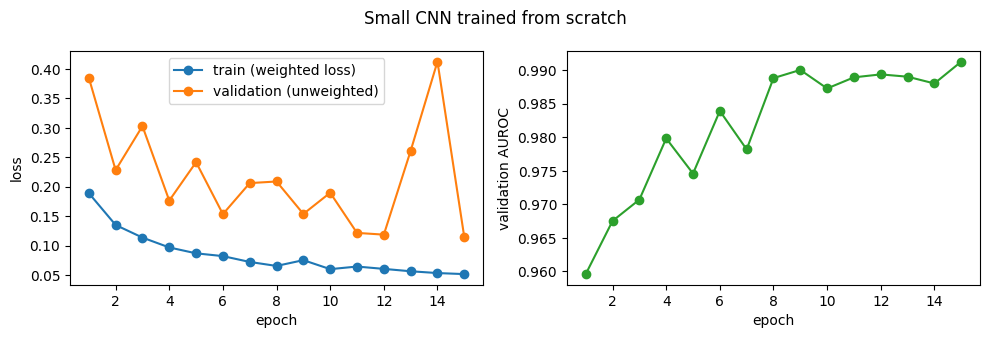

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.991,0.987,0.852,0.950,0.958,0.952


In [9]:
cnn, hist_cnn = train_model(cnn, epochs=15, lr=1e-3)
MODELS["cnn_scratch"] = TorchPredictor(cnn)
VAL_PRED["cnn_scratch"] = MODELS["cnn_scratch"].predict(IMAGES["val"])
plot_history(hist_cnn, "Small CNN trained from scratch")
val_table()

**Reading the loss curves.** The training loss uses class weights; the validation loss does not. Compare the *shape* of the two curves, not their absolute levels.

### Exercise 3.1 — Interpret the learning curves

✍️ **Your answer** (4–6 sentences):

1. Which epoch was kept, and why that one rather than the last?
2. Is there a sign of overfitting (training loss falling while validation loss rises or AUROC stops improving)? Point to the epochs.
3. Does the CNN beat the pixel logistic regression on validation AUROC? By how much, and is the gain large enough to justify a neural network?
4. The CNN has tens of thousands of parameters and 4,708 training images. Relate this to the lecture's discussion of overfitting.

## Part 4 — Transfer learning with a pretrained ResNet-18 (35 minutes)

ResNet-18 was trained on ImageNet colour photographs of 224 × 224 pixels. To reuse it:

- copy the single grey channel into three channels (red, green, blue);
- enlarge the 64 × 64 image to 128 × 128, so the network's downsampling does not shrink it to almost nothing;
- normalise with the ImageNet mean and standard deviation that the network was trained with;
- replace the final 1,000-class layer with a new layer that outputs one logit.

The next cell downloads the pretrained weights (about 45 MB) on first use.

In [10]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class PretrainedResNet(nn.Module):
    def __init__(self, weights=ResNet18_Weights.IMAGENET1K_V1, size=128):
        super().__init__()
        self.size = size
        self.backbone = resnet18(weights=weights)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, 1)   # new head: 512 features -> 1 logit
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

    def forward(self, x):                      # x: (n, 1, 64, 64), values 0-1
        x = F.interpolate(x, size=self.size, mode="bilinear", align_corners=False).repeat(1, 3, 1, 1)
        return self.backbone((x - self.mean) / self.std).squeeze(1)


resnet = PretrainedResNet()
print(f"ResNet-18 parameters: {count_params(resnet):,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /kaggle/working/lab12_data/torch/hub/checkpoints/resnet18-f37072fd.pth


  0%|          | 0.00/44.7M [00:00<?, ?B/s]

 16%|█▌        | 7.00M/44.7M [00:00<00:00, 73.2MB/s]

 56%|█████▋    | 25.1M/44.7M [00:00<00:00, 142MB/s] 

100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]

ResNet-18 parameters: 11,177,025


### Exercise 4.1 — Freeze the backbone

For **feature extraction**, only the new head (`backbone.fc`) is trained; every other layer is frozen. A parameter is frozen when its `requires_grad` attribute is `False`.

Complete `set_backbone_trainable(model, trainable)`: set `requires_grad = trainable` for every parameter of `model.backbone` **except** those of `model.backbone.fc`, which must always stay trainable.

In [11]:
def set_backbone_trainable(model, trainable):
    for name, parameter in model.backbone.named_parameters():
        parameter.requires_grad = bool(trainable) if not name.startswith("fc.") else True


set_backbone_trainable(resnet, False)
check("frozen: only the 512 + 1 head parameters are trainable", count_params(resnet, trainable_only=True) == 513)


PASS  frozen: only the 512 + 1 head parameters are trainable


**Stage A — feature extraction.** Train only the head, with a relatively high learning rate.

Note that `train_model` sets the model to training mode, so the frozen network's batch-normalisation statistics still adapt to the X-rays even though its weights do not. This is a common and usually harmless simplification.

epoch  1  train loss 0.223  val loss 0.484  val AUROC 0.951  (2.0 s)


epoch  2  train loss 0.129  val loss 0.297  val AUROC 0.971  (2.0 s)


epoch  3  train loss 0.109  val loss 0.210  val AUROC 0.974  (2.0 s)


epoch  4  train loss 0.098  val loss 0.209  val AUROC 0.975  (2.0 s)


epoch  5  train loss 0.093  val loss 0.195  val AUROC 0.977  (2.0 s)
kept epoch 5 (best val AUROC 0.977)


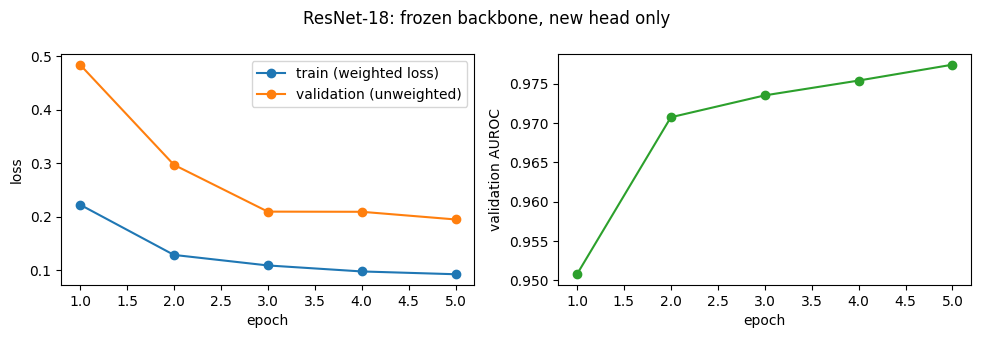

In [12]:
resnet, hist_head = train_model(resnet, epochs=5, lr=1e-3)
MODELS["resnet_features"] = TorchPredictor(deepcopy(resnet))
VAL_PRED["resnet_features"] = MODELS["resnet_features"].predict(IMAGES["val"])
plot_history(hist_head, "ResNet-18: frozen backbone, new head only")

**Stage B — fine-tuning.** Unfreeze all layers and continue from Stage A with a **ten times smaller** learning rate, so the pretrained weights change gently.

trainable parameters: 11,177,025


epoch  1  train loss 0.057  val loss 0.161  val AUROC 0.998  (5.6 s)


epoch  2  train loss 0.012  val loss 0.065  val AUROC 0.998  (5.5 s)


epoch  3  train loss 0.004  val loss 0.054  val AUROC 0.998  (5.5 s)


epoch  4  train loss 0.001  val loss 0.055  val AUROC 0.998  (5.6 s)


epoch  5  train loss 0.001  val loss 0.067  val AUROC 0.998  (5.6 s)


epoch  6  train loss 0.000  val loss 0.056  val AUROC 0.998  (5.6 s)
kept epoch 4 (best val AUROC 0.998)


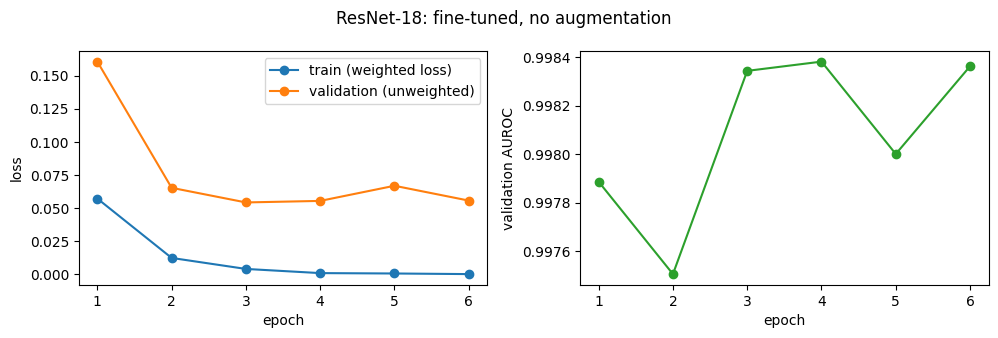

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.991,0.987,0.852,0.950,0.958,0.952
3,resnet_features,0.977,0.933,0.896,0.963,0.823,0.924
4,resnet_finetuned,0.998,0.987,0.948,0.982,0.962,0.977


In [13]:
resnet_ft = deepcopy(resnet)
set_backbone_trainable(resnet_ft, True)
print(f"trainable parameters: {count_params(resnet_ft, trainable_only=True):,}")
resnet_ft, hist_ft = train_model(resnet_ft, epochs=6, lr=1e-4)
MODELS["resnet_finetuned"] = TorchPredictor(resnet_ft)
VAL_PRED["resnet_finetuned"] = MODELS["resnet_finetuned"].predict(IMAGES["val"])
plot_history(hist_ft, "ResNet-18: fine-tuned, no augmentation")
val_table()

### Exercise 4.2 — Choose augmentations that keep the label true

`make_augment` builds a function that randomly modifies each training image in a batch. It supports four settings:

| Setting | Effect |
|---|---|
| `max_rotation_deg` | Rotate each image by a random angle in ± this many degrees |
| `max_shift_frac` | Shift by up to this fraction of the image width and height |
| `contrast` | Scale contrast by a random factor in 1 ± this value |
| `hflip` | If `True`, flip half the images left to right |

Set `AUGMENT_SETTINGS` to values you can justify for **chest X-rays**, using the lecture's Section 6.4. The default (all zero) does nothing. The cell shows one image under your settings so you can check that the results still look like plausible X-rays.

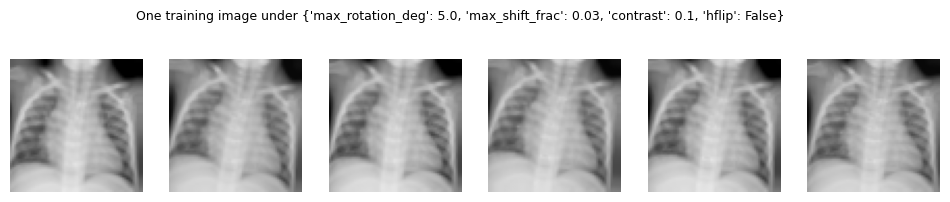

PASS  some augmentation chosen


In [14]:
def make_augment(max_rotation_deg=0.0, max_shift_frac=0.0, contrast=0.0, hflip=False):
    def augment(x):                            # x: (n, 1, h, w) on DEVICE, values 0-1
        n = x.shape[0]
        angle = (torch.rand(n, device=x.device) * 2 - 1) * np.deg2rad(max_rotation_deg)
        shift = (torch.rand(n, 2, device=x.device) * 2 - 1) * max_shift_frac * 2   # grid units span -1..1
        flip = torch.where(torch.rand(n, device=x.device) < 0.5, -1.0, 1.0) if hflip else torch.ones(n, device=x.device)
        cos, sin = torch.cos(angle), torch.sin(angle)
        theta = torch.stack([torch.stack([cos * flip, -sin, shift[:, 0]], 1),
                             torch.stack([sin * flip, cos, shift[:, 1]], 1)], 1)
        grid = F.affine_grid(theta, x.shape, align_corners=False)
        x = F.grid_sample(x, grid, padding_mode="border", align_corners=False)
        if contrast > 0:
            factor = 1 + (torch.rand(n, 1, 1, 1, device=x.device) * 2 - 1) * contrast
            mean = x.mean(dim=(2, 3), keepdim=True)
            x = ((x - mean) * factor + mean).clamp(0, 1)
        return x
    return augment


# TODO 4.2: choose values you can justify for chest X-rays
AUGMENT_SETTINGS = {"max_rotation_deg": 5.0, "max_shift_frac": 0.03, "contrast": 0.10, "hflip": False}

augment = make_augment(**AUGMENT_SETTINGS)
example = TENSORS["train"][:1].repeat(6, 1, 1, 1).to(DEVICE)
torch.manual_seed(SEED)
shown = augment(example).cpu()
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, img in zip(axes, shown):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
fig.suptitle(f"One training image under {AUGMENT_SETTINGS}", fontsize=9)
plt.show()
check("some augmentation chosen", any(v not in (0, 0.0, False) for v in AUGMENT_SETTINGS.values()))

**Stage C — fine-tuning with augmentation.** Same starting point (the Stage A model), same learning rate and epochs as Stage B; only the augmentation differs. Changing one thing at a time is what makes the comparison meaningful.

epoch  1  train loss 0.057  val loss 0.101  val AUROC 0.997  (5.7 s)


epoch  2  train loss 0.022  val loss 0.060  val AUROC 0.997  (5.8 s)


epoch  3  train loss 0.017  val loss 0.072  val AUROC 0.997  (5.8 s)


epoch  4  train loss 0.010  val loss 0.032  val AUROC 0.999  (5.9 s)


epoch  5  train loss 0.009  val loss 0.095  val AUROC 0.999  (5.9 s)


epoch  6  train loss 0.006  val loss 0.044  val AUROC 0.999  (5.9 s)
kept epoch 4 (best val AUROC 0.999)


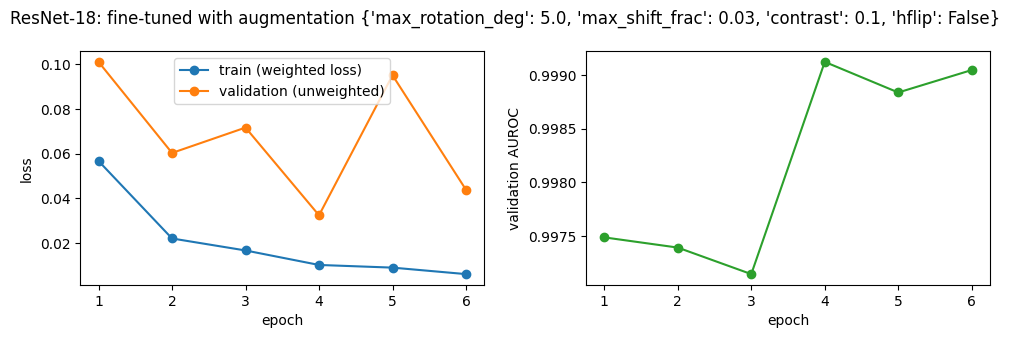

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
2,cnn_scratch,0.991,0.987,0.852,0.950,0.958,0.952
3,resnet_features,0.977,0.933,0.896,0.963,0.823,0.924
4,resnet_finetuned,0.998,0.987,0.948,0.982,0.962,0.977
5,resnet_finetuned_aug,0.999,0.990,0.978,0.992,0.971,0.987


In [15]:
resnet_aug = deepcopy(resnet)
set_backbone_trainable(resnet_aug, True)
resnet_aug, hist_aug = train_model(resnet_aug, epochs=6, lr=1e-4, augment=augment)
MODELS["resnet_finetuned_aug"] = TorchPredictor(resnet_aug)
VAL_PRED["resnet_finetuned_aug"] = MODELS["resnet_finetuned_aug"].predict(IMAGES["val"])
plot_history(hist_aug, f"ResNet-18: fine-tuned with augmentation {AUGMENT_SETTINGS}")
val_table()

### Exercise 4.3 — Interpret transfer learning

✍️ **Your answer** (6–8 sentences):

1. Justify each value in your `AUGMENT_SETTINGS`. Why did you (or did you not) allow a left–right flip?
2. Rank the five models by validation AUROC. Did transfer learning help compared with the CNN from scratch? Did fine-tuning help compared with feature extraction?
3. Did augmentation help? With six epochs and 524 validation images, how confident can you be in a small difference?
4. Compare the number of trainable parameters in Stage A (513) and Stage B. Why can Stage A still work reasonably well?
5. The comparison "pretrained ResNet versus SmallCNN" changes two things at once: the pretraining *and* the architecture. What extra experiment would separate the two effects? (See the optional extension.)

### Optional extension — isolate the effect of pretraining

If time allows, train the **same** ResNet-18 from random weights with the same schedule (all layers, `lr=1e-3`, 11 epochs). Add it to `VAL_PRED` as `"resnet_random_init"` and compare.

In [16]:
RUN_EXTENSION = False   # set to True to run (a few minutes on GPU)

if RUN_EXTENSION:
    resnet_rand = PretrainedResNet(weights=None)
    resnet_rand, hist_rand = train_model(resnet_rand, epochs=11, lr=1e-3)
    MODELS["resnet_random_init"] = TorchPredictor(resnet_rand)
    VAL_PRED["resnet_random_init"] = MODELS["resnet_random_init"].predict(IMAGES["val"])
    plot_history(hist_rand, "ResNet-18 from random initialisation")
    display(val_table())

## Part 5 — Choose, freeze, test once (15 minutes)

You now choose **one** model and **one** threshold using validation data only, then evaluate on the test set a single time.

**Threshold.** For a tool that helps prioritise X-rays for review, missing pneumonia is the costlier error. The helper below finds the highest threshold that still reaches a target **sensitivity** on the validation set.

### Exercise 5.1 — Make and justify your choice

Set `CHOSEN_MODEL` to one of the names in the validation table, and `TARGET_SENSITIVITY` to a value you can justify (for example 0.95). **Do not change either after running the test cell.**

In [17]:
def threshold_for_sensitivity(y_true, p, target):
    """Highest threshold whose sensitivity on (y_true, p) is at least target."""
    fpr, tpr, thresholds = roc_curve(y_true, p)
    ok = np.flatnonzero(tpr >= target)
    return float(min(thresholds[ok[0]], 1.0))


display(val_table().sort_values("auroc", ascending=False))

# TODO 5.1: choose a model name from the table and a target sensitivity
CHOSEN_MODEL = val_table().sort_values("auroc", ascending=False).iloc[0]["model"]
TARGET_SENSITIVITY = 0.95

THRESHOLD = threshold_for_sensitivity(LABELS["val"], VAL_PRED[CHOSEN_MODEL], TARGET_SENSITIVITY)
val_at_threshold = binary_metrics(LABELS["val"], VAL_PRED[CHOSEN_MODEL], THRESHOLD)
print(f"chosen: {CHOSEN_MODEL} | threshold {THRESHOLD:.3f} (chosen on validation)")
print({k: round(v, 3) if isinstance(v, float) else v for k, v in val_at_threshold.items()})

,model,auroc,sensitivity,specificity,ppv,npv,accuracy
5,resnet_finetuned_aug,0.999,0.990,0.978,0.992,0.971,0.987
4,resnet_finetuned,0.998,0.987,0.948,0.982,0.962,0.977
2,cnn_scratch,0.991,0.987,0.852,0.950,0.958,0.952
1,logreg_pixels,0.989,0.974,0.904,0.967,0.924,0.956
3,resnet_features,0.977,0.933,0.896,0.963,0.823,0.924
0,trivial,0.500,1.000,0.000,0.742,NaN,0.742


chosen: resnet_finetuned_aug | threshold 0.852 (chosen on validation)
{'auroc': np.float64(0.999), 'sensitivity': 0.977, 'specificity': 0.993, 'ppv': 0.997, 'npv': 0.937, 'accuracy': 0.981, 'tp': 380, 'fn': 9, 'tn': 134, 'fp': 1}


✍️ **Your answer** (2–3 sentences): why this model, and why this target sensitivity? What does the clinic pay for the chosen sensitivity, in terms of specificity on validation data?

### The single test evaluation

The cell below evaluates the frozen choice on the test set, adds a 95% bootstrap confidence interval for AUROC (resampling the 624 test images 1,000 times), and saves the results.

In [18]:
p_test = MODELS[CHOSEN_MODEL].predict(IMAGES["test"])
test_at_threshold = binary_metrics(LABELS["test"], p_test, THRESHOLD)

rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(p_test), len(p_test))
    if len(np.unique(LABELS["test"][i])) == 2:
        boot.append(roc_auc_score(LABELS["test"][i], p_test[i]))
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

final = pd.DataFrame([{"set": "validation", **val_at_threshold}, {"set": "test", **test_at_threshold}])
final.insert(1, "model", CHOSEN_MODEL)
final.insert(2, "threshold", THRESHOLD)
display(final.round(3))
print(f"test AUROC {test_at_threshold['auroc']:.3f} (95% bootstrap CI {ci_low:.3f}-{ci_high:.3f})")

results_file = DATA_DIR / "lab12_results.csv"
pd.concat([val_table().assign(set="validation", threshold=0.5), final.round(3)], ignore_index=True).to_csv(results_file, index=False)
if hasattr(MODELS[CHOSEN_MODEL], "model"):
    torch.save(MODELS[CHOSEN_MODEL].model.state_dict(), DATA_DIR / "lab12_chosen_model.pt")
print("saved", results_file)

,set,model,threshold,auroc,sensitivity,specificity,ppv,npv,accuracy,tp,fn,tn,fp
0,validation,resnet_finetuned_aug,0.852,0.999,0.977,0.993,0.997,0.937,0.981,380,9,134,1
1,test,resnet_finetuned_aug,0.852,0.985,0.997,0.838,0.911,0.995,0.938,389,1,196,38


test AUROC 0.985 (95% bootstrap CI 0.976-0.993)
saved /kaggle/working/lab12_data/lab12_results.csv


### Exercise 5.2 — Interpret the test result

✍️ **Your answer** (6–8 sentences):

1. Compare validation and test sensitivity, specificity and PPV at your threshold. Which changed most?
2. Give two reasons for the differences, using what you know about how `val` and `test` were made (Part 1).
3. How wide is the AUROC confidence interval? What does it tell you about claims such as "model A beats model B by 0.01"?
4. Is this test result an **external validation**? What would one require?
5. List three things that would be needed before such a model could be considered for use with real patients.

## Part 6 — Reflection (5 minutes)

✍️ **Your answer** (5–8 sentences): Write a short "training record" for your chosen model, as it would appear in a model card: data and splits used, preprocessing, architecture and pretraining, augmentation, number of epochs and selection rule, threshold and how it was chosen, test results with uncertainty, and the main limitations. Do not claim more than your results show.

## Grading rubric

| Criterion | Points |
|---|---:|
| Setup and Part 1: data loaded and verified; correct split summary; interpretation of unit of analysis, split provenance and prevalence | 15 |
| Part 2: correct metrics function; baseline interpretation | 15 |
| Part 3: CNN trained; learning curves interpreted with evidence from the epochs | 15 |
| Part 4: correct freezing; justified augmentation; honest comparison of the transfer-learning variants | 25 |
| Part 5: choice made on validation only; single test evaluation; interpretation of the validation–test gap, uncertainty and external validity | 20 |
| Part 6: training record that is specific, complete and does not over-claim | 10 |
| **Total** | **100** |

These points apply to this lab only. They are not course-assessment weights.

## References

- [Session 2 lecture notes](../lectures/session-02-model-development-training.md).
- Yang J et al. [MedMNIST v2 — A large-scale lightweight benchmark for 2D and 3D biomedical image classification](https://doi.org/10.1038/s41597-022-01721-8). *Scientific Data* 2023;10:41. Dataset files: [Zenodo record 10519652](https://zenodo.org/records/10519652).
- Kermany DS et al. [Identifying medical diagnoses and treatable diseases by image-based deep learning](https://doi.org/10.1016/j.cell.2018.02.010). *Cell* 2018;172(5):1122–1131.e9.
- He K et al. [Deep residual learning for image recognition](https://arxiv.org/abs/1512.03385). *CVPR* 2016. — the ResNet architecture.
- PyTorch. [torchvision ResNet-18](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html) model documentation.

## Written responses

### Exercise 1.2 — Interpret the split
Each row is one 64 × 64 chest X-ray image with a binary label, not one child. A child can contribute multiple images, and this dataset does not include patient identifiers, so image counts cannot be interpreted as counts of unique people. Validation was randomly separated from the source training pool, so images from the same patient or acquisition source may appear in both train and validation, making validation performance optimistic. PPV (and NPV) depends on class prevalence, so it can change between validation and test even with unchanged predictions. The pneumonia fraction in this curated dataset is not the prevalence in a children's clinic; clinic prevalence and patient mix affect predictive values and the practical workload from false alarms.

### Exercise 2.2 — Interpret the baselines
The trivial baseline predicts the training-set pneumonia fraction for every image; at a 0.5 threshold it labels every image positive. Its accuracy is therefore the pneumonia fraction, sensitivity is 1, and specificity is 0 (AUROC is 0.5 because all scores are tied). Its accuracy can look high because pneumonia is the majority class, but it cannot distinguish images. Pixel logistic regression's validation AUROC indicates how separable the labels are from coarse 32 × 32 intensity patterns alone; its exact result is shown in the validation table below.

### Exercise 3.1 — Interpret the CNN learning curves
The training loop retains the epoch with the best validation AUROC, rather than automatically keeping the last epoch, because later training can overfit. Use the saved learning curves to identify the epoch where validation AUROC peaks or validation loss begins to worsen while training loss falls. The validation table reports the CNN-to-logistic-regression AUROC difference; the comparison is descriptive and small validation samples make small differences uncertain. A CNN with many more parameters than there are independent patients can memorize image-specific details, especially because the dataset has image-level rather than patient-level identifiers and splits.

### Exercise 4.1 — Feature extraction
For Stage A only the final 513-parameter linear head is trainable; the frozen ResNet layers supply a fixed feature representation. In Stage B the full backbone is trainable, allowing adaptation to radiographs but increasing overfitting risk.

### Exercise 4.2 — Augmentation choice
I use small rotations (±5°), shifts of at most 3% of image width/height, and modest contrast jitter (±10%) because these can reflect positioning and exposure variation without radically changing anatomy. I do not use horizontal flips: although the binary label may remain the same, laterality and normal chest anatomy are not perfectly interchangeable, and flipping can create misleading anatomy.

### Exercise 4.3 — Transfer learning
The validation table ranks all five fitted models, and the curve plots show the selected epoch for each neural model. Transfer learning may help because ImageNet features provide useful low-level edges and shapes, but ImageNet is not a chest X-ray dataset. Fine-tuning versus frozen features and augmentation comparisons are noisy with only 524 validation images and a small epoch budget. Stage A needs only 513 trainable parameters, yet can work because it reuses a rich pretrained representation. To separate architecture from pretraining, train the same ResNet-18 architecture from random initialization with the same data, schedule and selection rule; the optional extension cell does this when enabled.

### Exercise 5.1 and 5.2 — Threshold, test and limitations
The selected model is chosen by validation AUROC and the threshold is the highest one meeting the 95% validation-sensitivity target; the test set is evaluated once after that choice is frozen. The executed output below reports the validation and test metrics and a bootstrap 95% AUROC interval. Differences may reflect sampling variation, the class-fraction shift between splits, and the lack of patient identifiers in the random validation split. This is not external validation: that would require a separate institution, time period or acquisition setting. Before clinical consideration, the model would need patient-level and external validation, calibration and subgroup/failure analysis, prospective workflow evaluation, and regulatory/clinical safety review.

### Reflection — Training record
The training record below is generated from the executed run and reports the chosen model, validation-selected threshold, test metrics and uncertainty. The data are 64 × 64 PneumoniaMNIST images with the supplied train/validation/test split; validation was randomly carved from the source training data and there are no patient identifiers. The selected architecture, pretrained weights, augmentation and epoch selection are recorded in the outputs. This is a teaching experiment on one curated dataset, not evidence of clinical readiness; test AUROC uncertainty, dataset shift, possible patient overlap in the random split and absence of clinical workflow testing limit conclusions.


In [19]:
# Result-linked answers and concise training record
baseline = val_table().set_index("model")
chosen = CHOSEN_MODEL
logreg_auc = float(baseline.loc["logreg_pixels", "auroc"])
cnn_auc = float(baseline.loc["cnn_scratch", "auroc"])
ranked = ", ".join(f"{r.model} ({r.auroc:.3f})" for r in val_table().sort_values("auroc", ascending=False).itertuples())
print("Validation AUROC ranking:", ranked)
print(f"Scratch CNN AUROC minus pixel logistic regression: {cnn_auc-logreg_auc:+.3f}.")
print(f"Chosen {chosen} at threshold {THRESHOLD:.3f}, selected on validation for target sensitivity {TARGET_SENSITIVITY:.0%}.")
print("Validation metrics:", {k: round(v, 3) if isinstance(v, (int, float, np.number)) else v for k,v in val_at_threshold.items()})
print("Test metrics:", {k: round(v, 3) if isinstance(v, (int, float, np.number)) else v for k,v in test_at_threshold.items()})
print(f"Test AUROC bootstrap 95% CI: {ci_low:.3f}–{ci_high:.3f}; width {ci_high-ci_low:.3f}.")
print(f"Training record: {chosen}; selected by validation AUROC/95% validation sensitivity target; threshold={THRESHOLD:.3f}; test AUROC={test_at_threshold['auroc']:.3f} (95% bootstrap CI {ci_low:.3f}–{ci_high:.3f}).")


Validation AUROC ranking: resnet_finetuned_aug (0.999), resnet_finetuned (0.998), cnn_scratch (0.991), logreg_pixels (0.989), resnet_features (0.977), trivial (0.500)
Scratch CNN AUROC minus pixel logistic regression: +0.002.
Chosen resnet_finetuned_aug at threshold 0.852, selected on validation for target sensitivity 95%.
Validation metrics: {'auroc': np.float64(0.999), 'sensitivity': 0.977, 'specificity': 0.993, 'ppv': 0.997, 'npv': 0.937, 'accuracy': 0.981, 'tp': 380, 'fn': 9, 'tn': 134, 'fp': 1}
Test metrics: {'auroc': np.float64(0.985), 'sensitivity': 0.997, 'specificity': 0.838, 'ppv': 0.911, 'npv': 0.995, 'accuracy': 0.938, 'tp': 389, 'fn': 1, 'tn': 196, 'fp': 38}
Test AUROC bootstrap 95% CI: 0.976–0.993; width 0.018.
Training record: resnet_finetuned_aug; selected by validation AUROC/95% validation sensitivity target; threshold=0.852; test AUROC=0.985 (95% bootstrap CI 0.976–0.993).


## Result-based interpretation of the Kaggle run

- **Data:** train = 4,708 images (1,214 normal; 3,494 pneumonia; 74.2% pneumonia); validation = 524 (135; 389; 74.2%); test = 624 (234; 390; 62.5%). That lower test fraction matters for PPV/NPV and makes the test split a useful distribution-shift check, though not an external clinical validation.
- **Baselines and scratch CNN:** at threshold 0.5 the trivial model had 74.2% accuracy, 100% sensitivity, 0% specificity and AUROC 0.500 because its scores are all tied. Pixel logistic regression reached validation AUROC 0.989; the scratch CNN reached 0.991, only +0.002. The scratch CNN's best validation AUROC was at epoch 15; validation loss varied and briefly worsened sharply at epoch 14 while train loss continued down, a sign to prefer checkpoint selection over assuming later epochs are always better.
- **Transfer learning ranking (learned models):** augmented fine-tuning 0.999, fine-tuning without augmentation 0.998, scratch CNN 0.991, pixel logistic regression 0.989, frozen feature extractor 0.977. The tiny validation differences should not be treated as reliable ordering; the validation set has 524 images. Stage A trained 513 parameters; full fine-tuning trained 11,177,025.
- **Threshold and test:** the validation-selected model was augmented fine-tuned ResNet-18 with threshold 0.852. Validation sensitivity/specificity/PPV were 0.977/0.993/0.997; test values were 0.997/0.838/0.911. Specificity and PPV fell the most, consistent with the test set's lower pneumonia fraction and split-specific sampling. Test AUROC was 0.985 with bootstrap 95% CI 0.976–0.993 (about 0.017 wide), so differences such as 0.01 between models are not persuasive from this single split. The held-out test images are from the same dataset source, so this is not external validation.

**Training record:** PneumoniaMNIST 64 × 64 grayscale images; supplied train/validation/test splits (random 9:1 train/validation split from source training data, source test as test); pixel values normalized to 0–1 with ImageNet preprocessing inside ResNet; ResNet-18 initialized with ImageNet weights and fine-tuned with ±5° rotation, ±3% translation, ±10% contrast and no horizontal flip for six epochs; best validation AUROC checkpoint selected (epoch 4); chosen threshold 0.852 selected on validation for at least 95% sensitivity. Test: AUROC 0.985 (95% bootstrap CI 0.976–0.993), sensitivity 0.997, specificity 0.838, PPV 0.911, NPV 0.995, accuracy 0.938. Limitations include image-level splits without patient IDs, dataset and prevalence shift, small validation set, threshold optimization on validation and no prospective or external clinical evaluation.
